In [4]:
import pandas as pd
import os

files = [
    '/aisles.csv',
    '/departments.csv',
    '/orders.csv',
    '/products.csv',
    '/order_products__prior.csv',
    '/order_products__train.csv'
]

for file in files:
    print(os.path.basename(file), ":", os.path.exists(file))

aisles.csv : True
departments.csv : True
orders.csv : True
products.csv : True
order_products__prior.csv : True
order_products__train.csv : True


# **Data Understanding**

In [5]:
import pandas as pd
import os

files = [
    '/aisles.csv',
    '/departments.csv',
    '/orders.csv',
    '/products.csv',
    '/order_products__prior.csv',
    '/order_products__train.csv'
]

for file in files:
    df = pd.read_csv(file, nrows=5)

    print("\n" + "="*60)
    print("DATASET:", os.path.basename(file))
    print("="*60)
    display(df)


DATASET: aisles.csv


,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation



DATASET: departments.csv


,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol



DATASET: orders.csv


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


... (2 outputs left out)


DATASET: order_products__prior.csv


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0



DATASET: order_products__train.csv


,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0
3,1,49683,4,0
4,1,43633,5,1


**Memeriksa Ukuran Dataset**

In [6]:
import pandas as pd
import os

files = [
    '/aisles.csv',
    '/departments.csv',
    '/orders.csv',
    '/products.csv',
    '/order_products__prior.csv',
    '/order_products__train.csv'
]

for file in files:
    total_rows = 0

    for chunk in pd.read_csv(file, chunksize=500000):
        total_rows += len(chunk)

    print(f"{os.path.basename(file)}: {total_rows:,} rows")

aisles.csv: 134 rows
departments.csv: 21 rows
orders.csv: 2,581,974 rows
products.csv: 49,688 rows
order_products__prior.csv: 4,896,902 rows
order_products__train.csv: 1,384,617 rows


**Missing Values Analysis**

In [7]:
import pandas as pd
import os

files = [
    '/aisles.csv',
    '/departments.csv',
    '/orders.csv',
    '/products.csv',
    '/order_products__prior.csv',
    '/order_products__train.csv'
]

for file in files:
    missing = None

    for chunk in pd.read_csv(file, chunksize=500000):
        chunk_missing = chunk.isnull().sum()

        if missing is None:
            missing = chunk_missing
        else:
            missing += chunk_missing

    print("\n==============================")
    print("DATASET:", os.path.basename(file))
    print("==============================")
    print(missing)


DATASET: aisles.csv
aisle_id    0
aisle       0
dtype: int64

DATASET: departments.csv
department_id    0
department       0
dtype: int64

DATASET: orders.csv
order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              1
days_since_prior_order    186936
dtype: int64

DATASET: products.csv
product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

DATASET: order_products__prior.csv
order_id             0
product_id           1
add_to_cart_order    1
reordered            1
dtype: int64

DATASET: order_products__train.csv
order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64


**Identifikasi Missing Values**

In [8]:
# 1. Missing value pada orders
orders = pd.read_csv('/orders.csv')

print("Missing Values - Orders:")
display(
    orders[orders.isnull().any(axis=1)]
)

# 2. Missing value pada order_products__prior
prior = pd.read_csv('/order_products__prior.csv')

print("\nMissing Values - Order Products Prior:")
display(
    prior[prior.isnull().any(axis=1)]
)

Missing Values - Orders:


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
11,2168274,2,prior,1,2,11,NaN
26,1374495,3,prior,1,1,14,NaN
39,3343014,4,prior,1,6,11,NaN
45,2717275,5,prior,1,3,12,NaN
...,...,...,...,...,...,...,...
3420930,969311,206205,prior,1,4,12,NaN
3420934,3189322,206206,prior,1,3,18,NaN
3421002,2166133,206207,prior,1,6,19,NaN
3421019,2227043,206208,prior,1,1,15,NaN



Missing Values - Order Products Prior:


,order_id,product_id,add_to_cart_order,reordered
7712550,814051,3,NaN,NaN


**Duplicate Data Analysis**

In [9]:
import pandas as pd
import os

files = [
    '/aisles.csv',
    '/departments.csv',
    '/orders.csv',
    '/products.csv',
    '/order_products__prior.csv',
    '/order_products__train.csv'
]

for file in files:

    df = pd.read_csv(file)

    print("\n==============================")
    print("DATASET:", os.path.basename(file))
    print("==============================")

    print("Total Rows:", len(df))
    print("Duplicate Rows:", df.duplicated().sum())


DATASET: aisles.csv
Total Rows: 134
Duplicate Rows: 0

DATASET: departments.csv
Total Rows: 21
Duplicate Rows: 0

DATASET: orders.csv
Total Rows: 3421083
Duplicate Rows: 0

DATASET: products.csv
Total Rows: 49688
Duplicate Rows: 0

DATASET: order_products__prior.csv
Total Rows: 10527825
Duplicate Rows: 0

DATASET: order_products__train.csv
Total Rows: 1384617
Duplicate Rows: 0


**Validasi Missing Values**

In [10]:
import pandas as pd

orders = pd.read_csv('/orders.csv')

print("Total Rows:", len(orders))

print("\nMissing Values per Column:")
print(orders.isnull().sum())

print("\nTotal Rows with Missing Values:")
print(orders.isnull().any(axis=1).sum())

print("\nMissing days_since_prior_order pada order pertama:")
print(
    orders[
        (orders['order_number'] == 1) &
        (orders['days_since_prior_order'].isnull())
    ].shape[0]
)

print("\nMissing days_since_prior_order selain order pertama:")
print(
    orders[
        (orders['order_number'] != 1) &
        (orders['days_since_prior_order'].isnull())
    ].shape[0]
)

Total Rows: 3421083

Missing Values per Column:
order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64

Total Rows with Missing Values:
206209

Missing days_since_prior_order pada order pertama:
206209

Missing days_since_prior_order selain order pertama:
0


# **Data Cleaning**

In [11]:
prior = pd.read_csv('/order_products__prior.csv')

missing_prior = prior[prior.isnull().any(axis=1)]

print("Rows with Missing Values:")
print(missing_prior)

print("\nMissing Values per Column:")
print(prior.isnull().sum())

Rows with Missing Values:
          order_id  product_id  add_to_cart_order  reordered
14518137   1531921       18599                NaN        NaN

Missing Values per Column:
order_id             0
product_id           0
add_to_cart_order    1
reordered            1
dtype: int64


In [12]:
print("Total Rows:", len(prior))
print("DataFrame Shape:", prior.shape)
print("Index Minimum:", prior.index.min())
print("Index Maximum:", prior.index.max())

print("\nData Missing:")
print(prior[prior.isnull().any(axis=1)])

Total Rows: 14518138
DataFrame Shape: (14518138, 4)
Index Minimum: 0
Index Maximum: 14518137

Data Missing:
          order_id  product_id  add_to_cart_order  reordered
14518137   1531921       18599                NaN        NaN


In [13]:
prior_clean = prior.dropna()

print("Total Rows Before Cleaning:", len(prior))
print("Total Rows After Cleaning:", len(prior_clean))
print("Rows Removed:", len(prior) - len(prior_clean))

print("\nMissing Values After Cleaning:")
print(prior_clean.isnull().sum())

Total Rows Before Cleaning: 14518138
Total Rows After Cleaning: 14518137
Rows Removed: 1

Missing Values After Cleaning:
order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64


In [14]:
prior_clean.to_csv('/order_products__prior_clean.csv', index=False)

print("Dataset berhasil disimpan!")

Dataset berhasil disimpan!


In [15]:
orders = pd.read_csv('/orders.csv')

orders_clean = orders.copy()

orders_clean.to_csv('/orders_clean.csv', index=False)

print("Total Rows:", len(orders_clean))
print("Total Missing Values:", orders_clean.isnull().sum().sum())
print("Dataset berhasil disimpan!")

Total Rows: 3421083
Total Missing Values: 206209
Dataset berhasil disimpan!


In [16]:
train = pd.read_csv('/order_products__train.csv')

print("Total Rows:", len(train))

print("\nMissing Values:")
print(train.isnull().sum())

print("\nDuplicate Rows:", train.duplicated().sum())

Total Rows: 1384617

Missing Values:
order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64

Duplicate Rows: 0


In [17]:
train_clean = train.copy()

train_clean.to_csv('/order_products__train_clean.csv', index=False)

print("Total Rows:", len(train_clean))
print("Dataset berhasil disimpan!")

Total Rows: 1384617
Dataset berhasil disimpan!


In [18]:
products = pd.read_csv('/products.csv')

print("Total Rows:", len(products))

print("\nMissing Values:")
print(products.isnull().sum())

print("\nDuplicate Rows:", products.duplicated().sum())

Total Rows: 49688

Missing Values:
product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

Duplicate Rows: 0


In [19]:
products_clean = products.copy()

products_clean.to_csv('/products_clean.csv', index=False)

print("Total Rows:", len(products_clean))
print("Dataset berhasil disimpan!")

Total Rows: 49688
Dataset berhasil disimpan!


In [20]:
aisles = pd.read_csv('/aisles.csv')

print("Total Rows:", len(aisles))

print("\nMissing Values:")
print(aisles.isnull().sum())

print("\nDuplicate Rows:", aisles.duplicated().sum())

Total Rows: 134

Missing Values:
aisle_id    0
aisle       0
dtype: int64

Duplicate Rows: 0


In [21]:
aisles_clean = aisles.copy()

aisles_clean.to_csv('/aisles_clean.csv', index=False)

print("Total Rows:", len(aisles_clean))
print("Dataset berhasil disimpan!")

Total Rows: 134
Dataset berhasil disimpan!


In [22]:
departments = pd.read_csv('/departments.csv')

print("Total Rows:", len(departments))

print("\nMissing Values:")
print(departments.isnull().sum())

print("\nDuplicate Rows:", departments.duplicated().sum())

Total Rows: 21

Missing Values:
department_id    0
department       0
dtype: int64

Duplicate Rows: 0


In [23]:
departments_clean = departments.copy()

departments_clean.to_csv('/departments_clean.csv', index=False)

print("Total Rows:", len(departments_clean))
print("Dataset berhasil disimpan!")

Total Rows: 21
Dataset berhasil disimpan!


# **Data Validation**

In [24]:
import os
import pandas as pd

cleaned_files = [
    '/aisles_clean.csv',
    '/departments_clean.csv',
    '/orders_clean.csv',
    '/products_clean.csv',
    '/order_products__prior_clean.csv',
    '/order_products__train_clean.csv'
]

for file in cleaned_files:
    print("\n" + "=" * 40)
    print("FILE:", os.path.basename(file))

    if os.path.exists(file):
        total_rows = sum(
            len(chunk)
            for chunk in pd.read_csv(file, chunksize=100000)
        )

        print("Status: File ditemukan")
        print("Total Rows:", total_rows)
        print("File Size:", round(os.path.getsize(file) / (1024**2), 2), "MB")
    else:
        print("Status: File tidak ditemukan")


FILE: aisles_clean.csv
Status: File ditemukan
Total Rows: 134
File Size: 0.0 MB

FILE: departments_clean.csv
Status: File ditemukan
Total Rows: 21
File Size: 0.0 MB

FILE: orders_clean.csv
Status: File ditemukan
Total Rows: 3421083
File Size: 103.33 MB

FILE: products_clean.csv
Status: File ditemukan
Total Rows: 49688
File Size: 2.07 MB

FILE: order_products__prior_clean.csv
Status: File ditemukan
Total Rows: 14518137
File Size: 296.38 MB

FILE: order_products__train_clean.csv
Status: File ditemukan
Total Rows: 1384617
File Size: 23.54 MB


**Validasi Relasi Antar Dataset**

In [25]:
import pandas as pd

# Load dimension tables
aisles = pd.read_csv('/aisles_clean.csv')
departments = pd.read_csv('/departments_clean.csv')
products = pd.read_csv('/products_clean.csv')

# Validasi primary key
print("=== PRIMARY KEY VALIDATION ===")

print("Duplicate aisle_id:",
      aisles['aisle_id'].duplicated().sum())

print("Duplicate department_id:",
      departments['department_id'].duplicated().sum())

print("Duplicate product_id:",
      products['product_id'].duplicated().sum())


# Validasi foreign key
print("\n=== FOREIGN KEY VALIDATION ===")

invalid_aisle = (
    ~products['aisle_id'].isin(aisles['aisle_id'])
).sum()

invalid_department = (
    ~products['department_id'].isin(departments['department_id'])
).sum()

print("Invalid aisle_id:", invalid_aisle)
print("Invalid department_id:", invalid_department)

=== PRIMARY KEY VALIDATION ===
Duplicate aisle_id: 0
Duplicate department_id: 0
Duplicate product_id: 0

=== FOREIGN KEY VALIDATION ===
Invalid aisle_id: 0
Invalid department_id: 0


**Validasi Relasi Transaksi**

In [26]:
import pandas as pd

# Load data
orders = pd.read_csv('/orders_clean.csv', usecols=['order_id'])
products = pd.read_csv('/products_clean.csv', usecols=['product_id'])

prior = pd.read_csv(
    '/order_products__prior_clean.csv',
    usecols=['order_id', 'product_id']
)

train = pd.read_csv(
    '/order_products__train_clean.csv',
    usecols=['order_id', 'product_id']
)

# Validasi order_products__prior
print("=== PRIOR TRANSACTION VALIDATION ===")

print("Invalid order_id:",
      (~prior['order_id'].isin(orders['order_id'])).sum())

print("Invalid product_id:",
      (~prior['product_id'].isin(products['product_id'])).sum())


# Validasi order_products__train
print("\n=== TRAIN TRANSACTION VALIDATION ===")

print("Invalid order_id:",
      (~train['order_id'].isin(orders['order_id'])).sum())

print("Invalid product_id:",
      (~train['product_id'].isin(products['product_id'])).sum())

=== PRIOR TRANSACTION VALIDATION ===
Invalid order_id: 0
Invalid product_id: 0

=== TRAIN TRANSACTION VALIDATION ===
Invalid order_id: 0
Invalid product_id: 0


# **Exploratory Data Analysis (EDA)**

**Order Distribution**

In [27]:
orders = pd.read_csv('/orders_clean.csv')

print("Order Day Distribution:")
print(orders['order_dow'].value_counts().sort_index())

print("\nOrder Hour Distribution:")
print(orders['order_hour_of_day'].value_counts().sort_index())

Order Day Distribution:
order_dow
0    600905
1    587478
2    467260
3    436972
4    426339
5    453368
6    448761
Name: count, dtype: int64

Order Hour Distribution:
order_hour_of_day
0      22758
1      12398
2       7539
3       5474
4       5527
5       9569
6      30529
7      91868
8     178201
9     257812
10    288418
11    284728
12    272841
13    277999
14    283042
15    283639
16    272553
17    228795
18    182912
19    140569
20    104292
21     78109
22     61468
23     40043
Name: count, dtype: int64


**Visualisasi Order by Day**

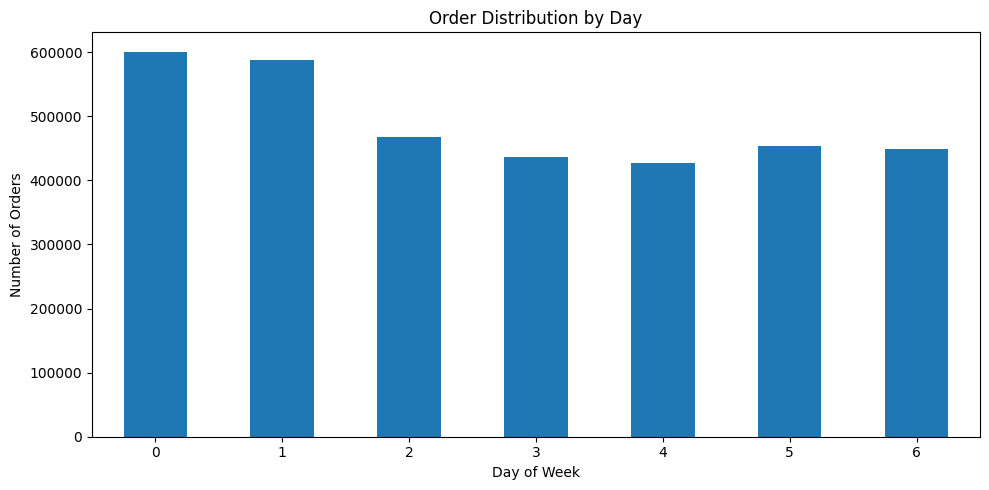

In [28]:
import matplotlib.pyplot as plt

day_orders = orders['order_dow'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
day_orders.plot(kind='bar')

plt.title('Order Distribution by Day')
plt.xlabel('Day of Week')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Grafik Distribusi Pesanan Berdasarkan Jam**

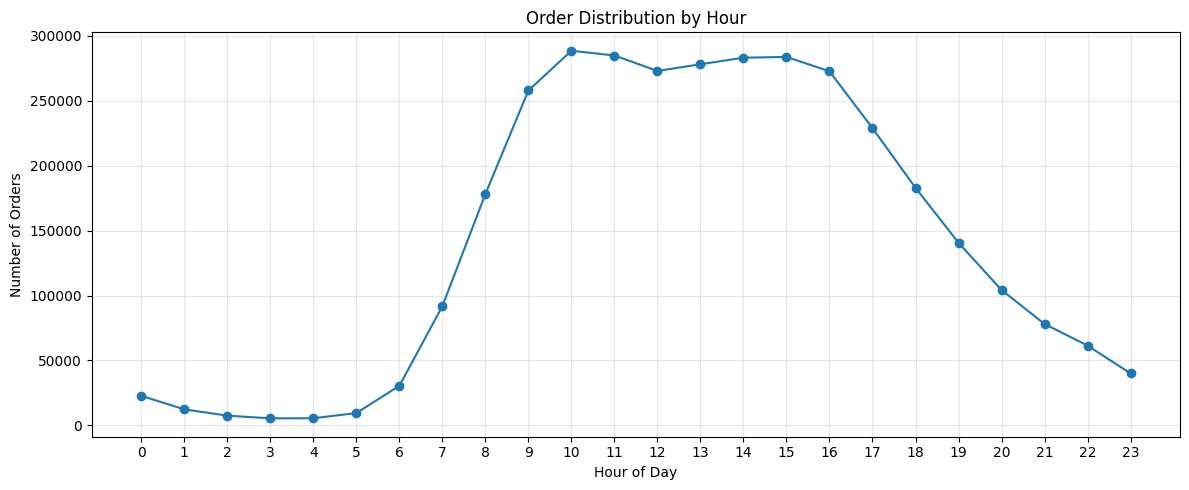

In [29]:
hour_orders = orders['order_hour_of_day'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
hour_orders.plot(kind='line', marker='o')

plt.title('Order Distribution by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Orders')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Distribusi Jumlah Pesanan Pelanggan**

In [30]:
customer_orders = orders.groupby('user_id')['order_id'].count()

print("Customer Order Statistics:")
print(customer_orders.describe())

Customer Order Statistics:
count    206209.000000
mean         16.590367
std          16.654774
min           4.000000
25%           6.000000
50%          10.000000
75%          20.000000
max         100.000000
Name: order_id, dtype: float64


**Visualisasi Customer Order Distribution**

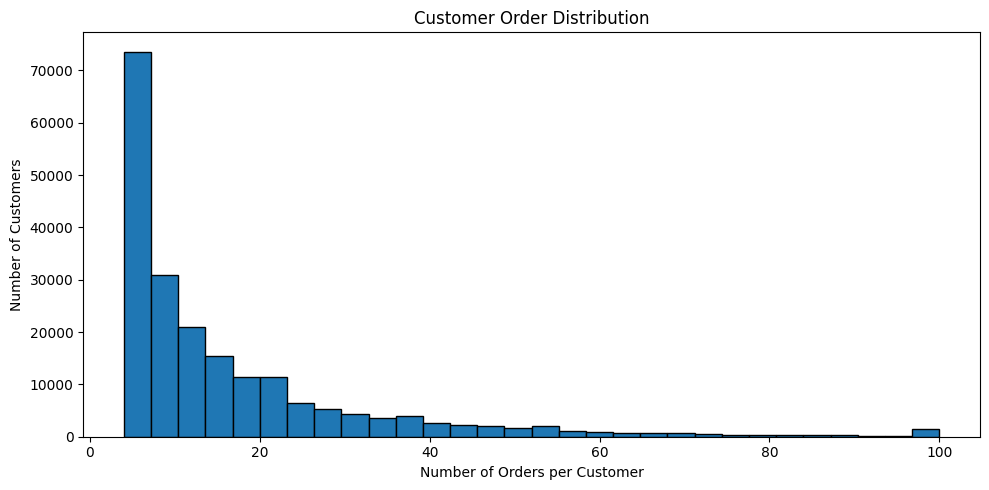

In [31]:
plt.figure(figsize=(10, 5))

plt.hist(customer_orders, bins=30, edgecolor='black')

plt.title('Customer Order Distribution')
plt.xlabel('Number of Orders per Customer')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

# **Reorder Analysis**

**Menghitung Reorder Distribution**

In [32]:
prior = pd.read_csv('/order_products__prior_clean.csv')
train = pd.read_csv('/order_products__train_clean.csv')

reorder_data = pd.concat(
    [prior['reordered'], train['reordered']],
    ignore_index=True
)

reorder_counts = reorder_data.value_counts().sort_index()

print("Reorder Distribution:")
print(reorder_counts)

print("\nReorder Percentage:")
print(reorder_data.value_counts(normalize=True).sort_index() * 100)

Reorder Distribution:
reordered
0.0    6508679
1.0    9394075
Name: count, dtype: int64

Reorder Percentage:
reordered
0.0    40.927999
1.0    59.072001
Name: proportion, dtype: float64


**Visualisasi Reorder Distribution**

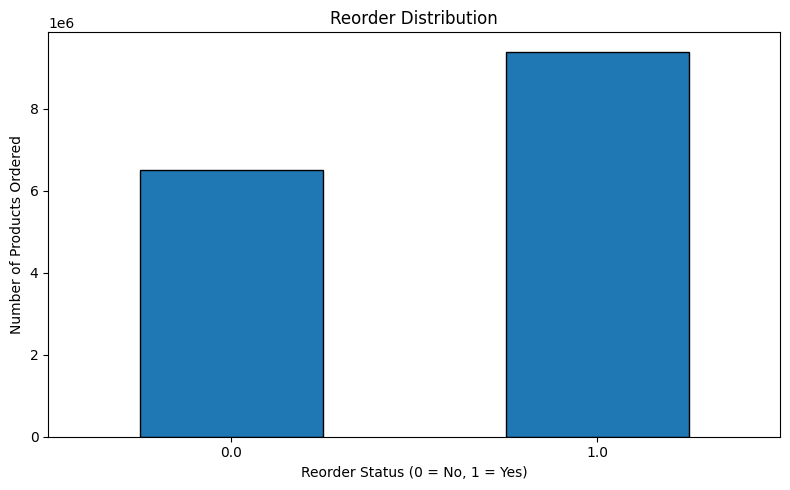

In [33]:
plt.figure(figsize=(8, 5))

reorder_counts.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Reorder Distribution')
plt.xlabel('Reorder Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Products Ordered')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# **Product Analysis**

**Top 10 Most Ordered Products**

In [34]:
# Menggabungkan jumlah pembelian berdasarkan product_id
product_counts = pd.concat([
    prior['product_id'],
    train['product_id']
]).value_counts()

# Mengambil 10 produk teratas
top_10_products = product_counts.head(10)

# Menggabungkan dengan nama produk
products = pd.read_csv('/products_clean.csv')

top_products = (
    products[products['product_id'].isin(top_10_products.index)]
    .set_index('product_id')
    .loc[top_10_products.index]
    .reset_index()
)

top_products['total_orders'] = top_10_products.values

print(top_products[['product_id', 'product_name', 'total_orders']])

   product_id            product_name  total_orders
0       24852                  Banana        230835
1       13176  Bag of Organic Bananas        185458
2       21137    Organic Strawberries        129897
3       21903    Organic Baby Spinach        117696
4       47209    Organic Hass Avocado        102870
5       47766         Organic Avocado         86195
6       47626             Large Lemon         76326
7       16797            Strawberries         70325
8       26209                   Limes         68998
9       27845      Organic Whole Milk         66695


**Visualisasi Top 10 Products**

<Figure size 1000x600 with 0 Axes>

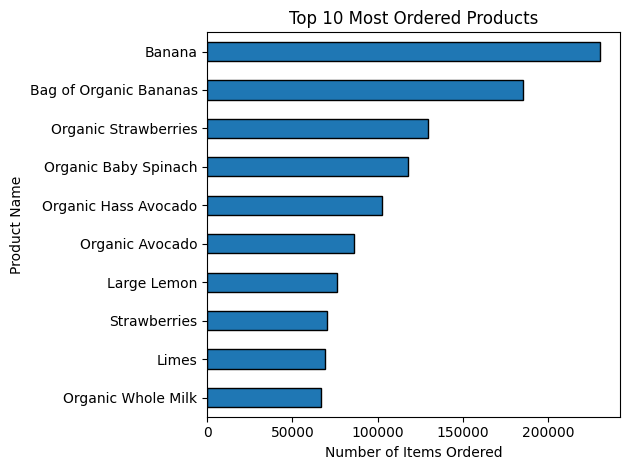

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

top_products.sort_values('total_orders').plot(
    x='product_name',
    y='total_orders',
    kind='barh',
    legend=False,
    edgecolor='black'
)

plt.title('Top 10 Most Ordered Products')
plt.xlabel('Number of Items Ordered')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

# **Category Analysis**

**Menghitung jumlah pembelian per department**

In [36]:
# Menggabungkan jumlah pembelian produk dengan informasi produk
product_analysis = (
    product_counts.rename('total_orders')
    .reset_index()
    .rename(columns={'index': 'product_id'})
    .merge(products, on='product_id')
)

# Menggabungkan informasi department
departments = pd.read_csv('/departments_clean.csv')

product_analysis = product_analysis.merge(
    departments,
    on='department_id'
)

# Menghitung total pembelian setiap department
department_counts = (
    product_analysis.groupby('department')
    ['total_orders']
    .sum()
    .sort_values(ascending=False)
)

print(department_counts)

department
produce            4653754
dairy eggs         2640689
snacks             1412078
beverages          1317228
frozen             1101714
pantry              919305
bakery              575569
canned goods        524221
deli                515590
dry goods pasta     426666
household           366229
breakfast           347435
meat seafood        347148
personal care       221427
babies              205217
international       132832
alcohol              74153
pets                 48044
missing              38811
other                17927
bulk                 16717
Name: total_orders, dtype: int64


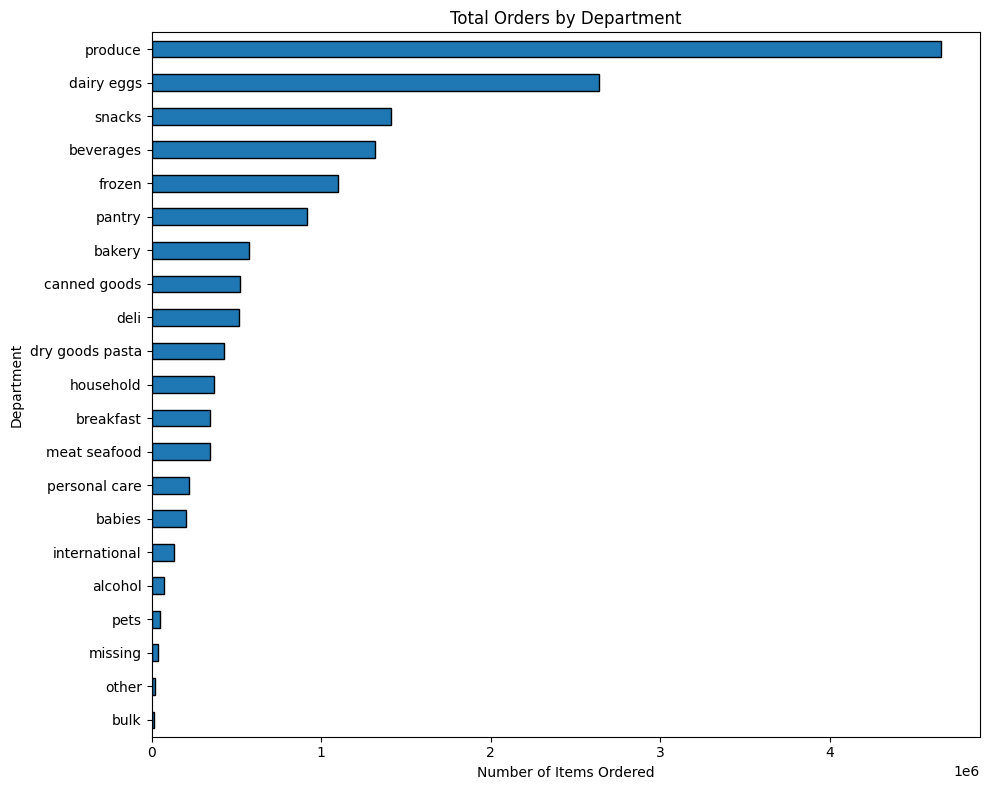

In [37]:
plt.figure(figsize=(10, 8))

department_counts.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Total Orders by Department')
plt.xlabel('Number of Items Ordered')
plt.ylabel('Department')
plt.tight_layout()
plt.show()

**Menghitung 10 Aisle dengan Pembelian Tertinggi**

In [38]:
# Menggabungkan data produk dengan informasi aisle
aisles = pd.read_csv('/aisles_clean.csv')

aisle_analysis = product_analysis.merge(
    aisles,
    on='aisle_id'
)

# Menghitung total pembelian per aisle
aisle_counts = (
    aisle_analysis.groupby('aisle')
    ['total_orders']
    .sum()
    .sort_values(ascending=False)
)

# Menampilkan 10 aisle teratas
top_10_aisles = aisle_counts.head(10)

print(top_10_aisles)

aisle
fresh fruits                     1782152
fresh vegetables                 1680366
packaged vegetables fruits        868981
yogurt                            705248
packaged cheese                   479837
milk                              431923
water seltzer sparkling water     412584
chips pretzels                    355194
soy lactosefree                   312351
bread                             285912
Name: total_orders, dtype: int64


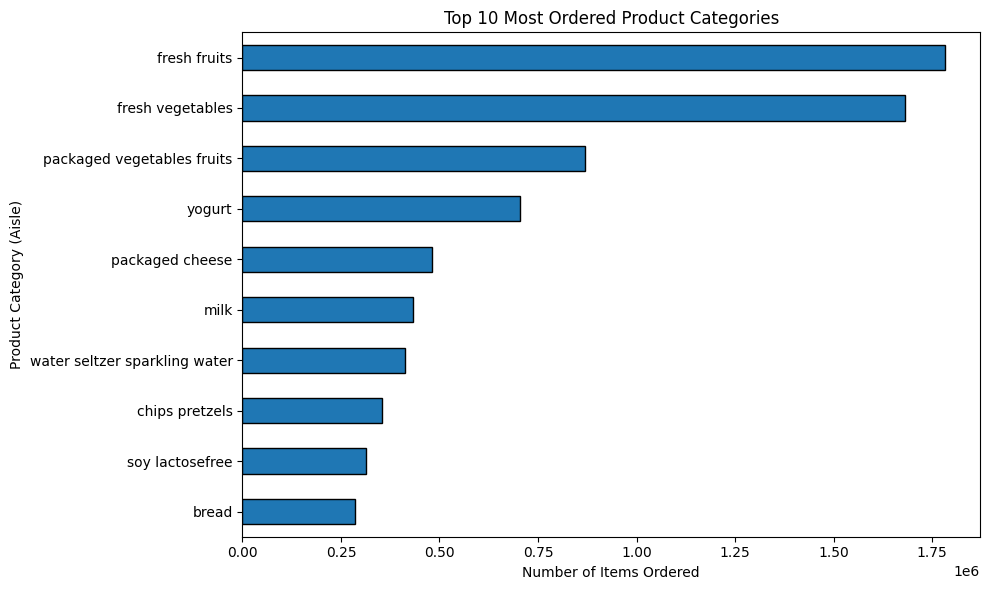

In [39]:
plt.figure(figsize=(10, 6))

top_10_aisles.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Most Ordered Product Categories')
plt.xlabel('Number of Items Ordered')
plt.ylabel('Product Category (Aisle)')
plt.tight_layout()
plt.show()

# **Basket Analysis**

**Menghitung jumlah item per pesanan**

In [40]:
# Menggabungkan jumlah item berdasarkan order_id
order_items = pd.concat([
    prior['order_id'],
    train['order_id']
])

# Menghitung jumlah item dalam setiap pesanan
basket_size = order_items.value_counts()

# Statistik ukuran keranjang belanja
print(basket_size.describe())

count    1.570291e+06
mean     1.012727e+01
std      7.559973e+00
min      1.000000e+00
25%      5.000000e+00
50%      8.000000e+00
75%      1.400000e+01
max      1.370000e+02
Name: count, dtype: float64


**Membuat Histogram Basket Size**

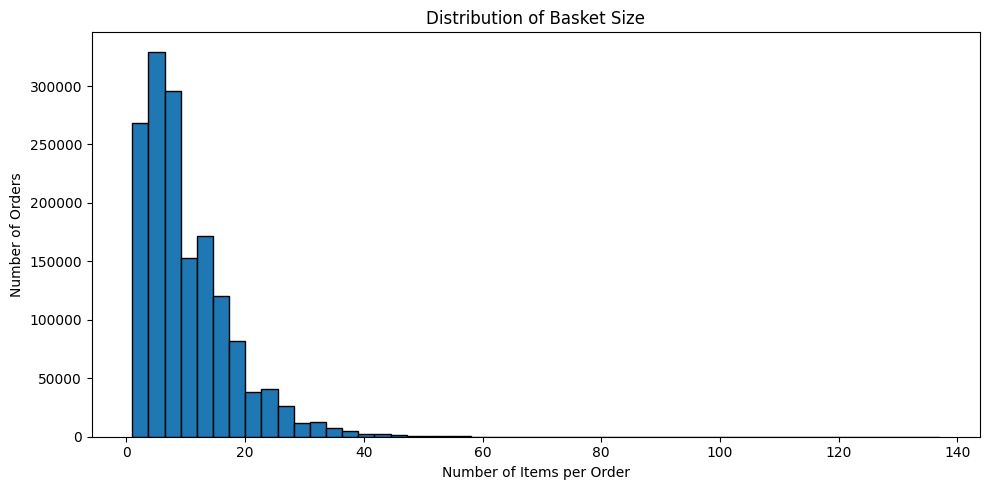

In [41]:
plt.figure(figsize=(10, 5))

plt.hist(basket_size, bins=50, edgecolor='black')

plt.title('Distribution of Basket Size')
plt.xlabel('Number of Items per Order')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

# **Customer Retention Behavior**

**Menghitung interval pemesanan**

In [42]:
# Mengambil data interval antar pemesanan
order_intervals = orders['days_since_prior_order'].dropna()

# Statistik interval pemesanan
print(order_intervals.describe())

# Frekuensi interval pemesanan
print("\nOrder Interval Distribution:")
print(order_intervals.value_counts().sort_index())

count    3.214874e+06
mean     1.111484e+01
std      9.206737e+00
min      0.000000e+00
25%      4.000000e+00
50%      7.000000e+00
75%      1.500000e+01
max      3.000000e+01
Name: days_since_prior_order, dtype: float64

Order Interval Distribution:
days_since_prior_order
0.0      67755
1.0     145247
2.0     193206
3.0     217005
4.0     221696
5.0     214503
6.0     240013
7.0     320608
8.0     181717
9.0     118188
10.0     95186
11.0     80970
12.0     76146
13.0     83214
14.0    100230
15.0     66579
16.0     46941
17.0     39245
18.0     35881
19.0     34384
20.0     38527
21.0     45470
22.0     32012
23.0     23885
24.0     20712
25.0     19234
26.0     19016
27.0     22013
28.0     26777
29.0     19191
30.0    369323
Name: count, dtype: int64


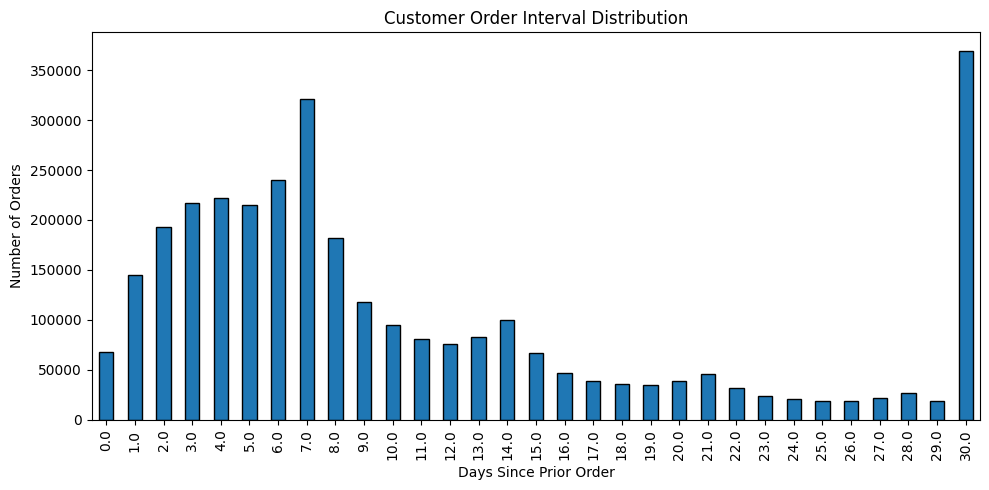

In [43]:
plt.figure(figsize=(10, 5))

order_intervals.value_counts().sort_index().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Customer Order Interval Distribution')
plt.xlabel('Days Since Prior Order')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

# **SQL Analysis**

In [44]:
import sqlite3

# Membuat koneksi database
conn = sqlite3.connect('/instacart.db')

# Membuat cursor
cursor = conn.cursor()

print("Database SQLite berhasil dibuat!")

Database SQLite berhasil dibuat!


In [45]:
import pandas as pd

# Membaca dataset hasil cleaning
aisles = pd.read_csv('/aisles_clean.csv')
departments = pd.read_csv('/departments_clean.csv')
orders = pd.read_csv('/orders_clean.csv')
products = pd.read_csv('/products_clean.csv')
prior = pd.read_csv('/order_products__prior_clean.csv')
train = pd.read_csv('/order_products__train_clean.csv')

print("Semua dataset berhasil dibaca!")

Semua dataset berhasil dibaca!


In [46]:
# Memasukkan dataset ke database SQLite

aisles.to_sql('aisles', conn, if_exists='replace', index=False)
departments.to_sql('departments', conn, if_exists='replace', index=False)
orders.to_sql('orders', conn, if_exists='replace', index=False)
products.to_sql('products', conn, if_exists='replace', index=False)
prior.to_sql('order_products_prior', conn, if_exists='replace', index=False)
train.to_sql('order_products_train', conn, if_exists='replace', index=False)

# Menyimpan perubahan
conn.commit()

print("Semua dataset berhasil dimasukkan ke SQLite!")

Semua dataset berhasil dimasukkan ke SQLite!


In [47]:
# Mengecek daftar tabel dalam database
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;",
    conn
)

print("Daftar Tabel:")
print(tables)

# Mengecek jumlah baris setiap tabel
table_names = [
    'aisles',
    'departments',
    'orders',
    'products',
    'order_products_prior',
    'order_products_train'
]

print("\nJumlah Baris:")
for table in table_names:
    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS total_rows FROM {table}",
        conn
    )
    print(f"{table}: {count.iloc[0, 0]:,}")

Daftar Tabel:
                   name
0                aisles
1           departments
2  order_products_prior
3  order_products_train
4                orders
5              products

Jumlah Baris:
aisles: 134
departments: 21
orders: 3,421,083
products: 49,688
order_products_prior: 14,518,137
order_products_train: 1,384,617


**Total orders**

In [48]:
query = """
SELECT COUNT(*) AS total_orders
FROM orders;
"""

result = pd.read_sql_query(query, conn)
print(result)

   total_orders
0       3421083


**Total Customers**

In [49]:
query = """
SELECT COUNT(DISTINCT user_id) AS total_customers
FROM orders;
"""

result = pd.read_sql_query(query, conn)
print(result)

   total_customers
0           206209


In [50]:
query = """
SELECT
    AVG(total_orders) AS avg_orders_per_customer
FROM (
    SELECT
        user_id,
        COUNT(order_id) AS total_orders
    FROM orders
    GROUP BY user_id
);
"""

result = pd.read_sql_query(query, conn)
print(result)

   avg_orders_per_customer
0                16.590367


In [51]:
query = """
SELECT
    p.product_id,
    p.product_name,
    COUNT(*) AS total_orders
FROM (
    SELECT product_id FROM order_products_prior
    UNION ALL
    SELECT product_id FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
GROUP BY p.product_id, p.product_name
ORDER BY total_orders DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

   product_id            product_name  total_orders
0       24852                  Banana        230835
1       13176  Bag of Organic Bananas        185458
2       21137    Organic Strawberries        129897
3       21903    Organic Baby Spinach        117696
4       47209    Organic Hass Avocado        102870
5       47766         Organic Avocado         86195
6       47626             Large Lemon         76326
7       16797            Strawberries         70325
8       26209                   Limes         68998
9       27845      Organic Whole Milk         66695


In [52]:
query = """
SELECT
    d.department,
    COUNT(*) AS total_orders
FROM (
    SELECT product_id FROM order_products_prior
    UNION ALL
    SELECT product_id FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
JOIN departments d
    ON p.department_id = d.department_id
GROUP BY d.department
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, conn)
print(result)

         department  total_orders
0           produce       4653754
1        dairy eggs       2640689
2            snacks       1412078
3         beverages       1317228
4            frozen       1101714
5            pantry        919305
6            bakery        575569
7      canned goods        524221
8              deli        515590
9   dry goods pasta        426666
10        household        366229
11        breakfast        347435
12     meat seafood        347148
13    personal care        221427
14           babies        205217
15    international        132832
16          alcohol         74153
17             pets         48044
18          missing         38811
19            other         17927
20             bulk         16717


In [53]:
query = """
SELECT
    AVG(total_products) AS avg_basket_size
FROM (
    SELECT
        order_id,
        COUNT(*) AS total_products
    FROM (
        SELECT order_id FROM order_products_prior
        UNION ALL
        SELECT order_id FROM order_products_train
    )
    GROUP BY order_id
);
"""

result = pd.read_sql_query(query, conn)
print(result)

   avg_basket_size
0        10.127266


In [54]:
query = """
SELECT
    COUNT(*) AS total_product_orders,
    SUM(reordered) AS total_reordered,
    ROUND(
        100.0 * SUM(reordered) / COUNT(*), 2
    ) AS reorder_rate
FROM (
    SELECT reordered FROM order_products_prior
    UNION ALL
    SELECT reordered FROM order_products_train
);
"""

result = pd.read_sql_query(query, conn)
print(result)

   total_product_orders  total_reordered  reorder_rate
0              15902754        9394075.0         59.07


In [55]:
query = """
SELECT
    order_hour_of_day,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_hour_of_day
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, conn)
print(result)

    order_hour_of_day  total_orders
0                  10        288418
1                  11        284728
2                  15        283639
3                  14        283042
4                  13        277999
5                  12        272841
6                  16        272553
7                   9        257812
8                  17        228795
9                  18        182912
10                  8        178201
11                 19        140569
12                 20        104292
13                  7         91868
14                 21         78109
15                 22         61468
16                 23         40043
17                  6         30529
18                  0         22758
19                  1         12398
20                  5          9569
21                  2          7539
22                  4          5527
23                  3          5474


In [56]:
query = """
SELECT
    order_dow,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_dow
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, conn)
print(result)

   order_dow  total_orders
0          0        600905
1          1        587478
2          2        467260
3          5        453368
4          6        448761
5          3        436972
6          4        426339


In [57]:
query = """
SELECT
    ROUND(AVG(days_since_prior_order), 2) AS avg_days_between_orders,
    MIN(days_since_prior_order) AS min_days,
    MAX(days_since_prior_order) AS max_days
FROM orders
WHERE days_since_prior_order IS NOT NULL;
"""

result = pd.read_sql_query(query, conn)
print(result)

   avg_days_between_orders  min_days  max_days
0                    11.11       0.0      30.0


**Top 10 Aisles berdasarkan jumlah pemesanan**

In [58]:
query = """
SELECT
    a.aisle,
    COUNT(*) AS total_orders
FROM (
    SELECT product_id FROM order_products_prior
    UNION ALL
    SELECT product_id FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
JOIN aisles a
    ON p.aisle_id = a.aisle_id
GROUP BY a.aisle
ORDER BY total_orders DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

                           aisle  total_orders
0                   fresh fruits       1782152
1               fresh vegetables       1680366
2     packaged vegetables fruits        868981
3                         yogurt        705248
4                packaged cheese        479837
5                           milk        431923
6  water seltzer sparkling water        412584
7                 chips pretzels        355194
8                soy lactosefree        312351
9                          bread        285912


In [59]:
query = """
SELECT
    p.product_id,
    p.product_name,
    COUNT(*) AS total_reorders
FROM order_products_prior op
JOIN products p
    ON op.product_id = p.product_id
WHERE op.reordered = 1
GROUP BY p.product_id, p.product_name
ORDER BY total_reorders DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

   product_id            product_name  total_reorders
0       24852                  Banana          178706
1       13176  Bag of Organic Bananas          141599
2       21137    Organic Strawberries           92459
3       21903    Organic Baby Spinach           83465
4       47209    Organic Hass Avocado           75954
5       47766         Organic Avocado           59635
6       27845      Organic Whole Milk           51331
7       47626             Large Lemon           47388
8       27966     Organic Raspberries           46739
9       16797            Strawberries           44585


In [60]:
query = """
SELECT
    p.product_id,
    p.product_name,
    COUNT(*) AS total_reorders
FROM (
    SELECT product_id, reordered FROM order_products_prior
    UNION ALL
    SELECT product_id, reordered FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
WHERE op.reordered = 1
GROUP BY p.product_id, p.product_name
ORDER BY total_reorders DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

   product_id            product_name  total_reorders
0       24852                  Banana          195263
1       13176  Bag of Organic Bananas          154961
2       21137    Organic Strawberries          101062
3       21903    Organic Baby Spinach           91520
4       47209    Organic Hass Avocado           81996
5       47766         Organic Avocado           65861
6       27845      Organic Whole Milk           55505
7       47626             Large Lemon           53311
8       27966     Organic Raspberries           51018
9       16797            Strawberries           49371


**Top 10 Products by First Time Purchase**

In [61]:
query = """
SELECT
    p.product_id,
    p.product_name,
    COUNT(*) AS total_first_purchases
FROM (
    SELECT product_id, reordered FROM order_products_prior
    UNION ALL
    SELECT product_id, reordered FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
WHERE op.reordered = 0
GROUP BY p.product_id, p.product_name
ORDER BY total_first_purchases DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

   product_id            product_name  total_first_purchases
0       24852                  Banana                  35572
1       13176  Bag of Organic Bananas                  30497
2       21137    Organic Strawberries                  28835
3       21903    Organic Baby Spinach                  26176
4       47626             Large Lemon                  23015
5       26209                   Limes                  21976
6       16797            Strawberries                  20954
7       47209    Organic Hass Avocado                  20874
8       47766         Organic Avocado                  20334
9       39275     Organic Blueberries                  18378


**Top 10 Customers by Total Orders**

In [62]:
query = """
SELECT
    user_id,
    COUNT(order_id) AS total_orders
FROM orders
GROUP BY user_id
ORDER BY total_orders DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

   user_id  total_orders
0   206105           100
1   205972           100
2   205878           100
3   205543           100
4   205483           100
5   205405           100
6   205237           100
7   204887           100
8   204709           100
9   204485           100


**Top 10 Customers by Average Days Between Orders**

In [63]:
query = """
SELECT
    user_id,
    ROUND(AVG(days_since_prior_order), 2) AS avg_days_between_orders,
    COUNT(days_since_prior_order) AS total_order_intervals
FROM orders
WHERE days_since_prior_order IS NOT NULL
GROUP BY user_id
HAVING COUNT(days_since_prior_order) >= 3
ORDER BY avg_days_between_orders ASC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

   user_id  avg_days_between_orders  total_order_intervals
0    14433                     0.00                      6
1    74329                     0.00                      5
2    80567                     0.00                      3
3   109010                     0.00                      3
4   164320                     0.00                      3
5   201321                     0.00                      3
6   138747                     0.17                      6
7    46408                     0.23                     99
8   168850                     0.25                      4
9   134572                     0.29                     99


**Top 10 Customers by Total Products Purchased**

In [64]:
query = """
SELECT
    o.user_id,
    COUNT(*) AS total_products_purchased
FROM orders o
JOIN (
    SELECT order_id, product_id FROM order_products_prior
    UNION ALL
    SELECT order_id, product_id FROM order_products_train
) op
    ON o.order_id = op.order_id
GROUP BY o.user_id
ORDER BY total_products_purchased DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

   user_id  total_products_purchased
0   176478                      1620
1   137629                      1511
2   160106                      1406
3   201268                      1376
4   164055                      1352
5   182401                      1339
6   145686                      1295
7   129928                      1261
8   186704                      1254
9    33731                      1219


**Top 10 Products with Highest Reorder Rate**

In [65]:
query = """
SELECT
    p.product_id,
    p.product_name,
    COUNT(*) AS total_orders,
    SUM(op.reordered) AS total_reorders,
    ROUND(100.0 * SUM(op.reordered) / COUNT(*), 2) AS reorder_rate
FROM (
    SELECT product_id, reordered FROM order_products_prior
    UNION ALL
    SELECT product_id, reordered FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
GROUP BY p.product_id, p.product_name
HAVING COUNT(*) >= 1000
ORDER BY reorder_rate DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

   product_id                     product_name  total_orders  total_reorders  \
0       45504       Whole Organic Omega 3 Milk          4422          3812.0   
1       43394  Organic Lactose Free Whole Milk          4131          3552.0   
2        5514   Organic Homogenized Whole Milk          1908          1640.0   
3       29447         Milk, Organic, Vitamin D          9602          8216.0   
4       38689         Organic Reduced Fat Milk         17206         14691.0   
5        9292  Half And Half Ultra Pasteurized          1383          1179.0   
6       34197                        Goat Milk          2471          2094.0   
7       24852                           Banana        230835        195263.0   
8       31720              Organic  Whole Milk          4580          3854.0   
9       29118       French Vanilla Soy Creamer          1726          1448.0   

   reorder_rate  
0         86.21  
1         85.98  
2         85.95  
3         85.57  
4         85.38  
5         8

In [66]:
query = """
SELECT
    o.order_hour_of_day,
    ROUND(AVG(op.total_products), 2) AS avg_basket_size,
    COUNT(*) AS total_orders
FROM orders o
JOIN (
    SELECT order_id, COUNT(*) AS total_products
    FROM (
        SELECT order_id FROM order_products_prior
        UNION ALL
        SELECT order_id FROM order_products_train
    )
    GROUP BY order_id
) op
    ON o.order_id = op.order_id
GROUP BY o.order_hour_of_day
ORDER BY o.order_hour_of_day;
"""

result = pd.read_sql_query(query, conn)
print(result)

    order_hour_of_day  avg_basket_size  total_orders
0                   0            10.22         10355
1                   1            10.03          5700
2                   2             9.91          3496
3                   3            10.17          2491
4                   4            10.30          2586
5                   5             9.85          4468
6                   6            10.15         14097
7                   7            10.35         42295
8                   8            10.25         81788
9                   9            10.12        118046
10                 10            10.20        132231
11                 11            10.25        130328
12                 12            10.26        125300
13                 13            10.22        127528
14                 14            10.21        129953
15                 15            10.06        130109
16                 16             9.95        124961
17                 17             9.81        

In [67]:
query = """
SELECT
    o.order_dow,
    ROUND(AVG(op.total_products), 2) AS avg_basket_size,
    COUNT(*) AS total_orders
FROM orders o
JOIN (
    SELECT order_id, COUNT(*) AS total_products
    FROM (
        SELECT order_id FROM order_products_prior
        UNION ALL
        SELECT order_id FROM order_products_train
    )
    GROUP BY order_id
) op
    ON o.order_id = op.order_id
GROUP BY o.order_dow
ORDER BY o.order_dow;
"""

result = pd.read_sql_query(query, conn)
print(result)

   order_dow  avg_basket_size  total_orders
0          0            11.21        277218
1          1            10.19        269345
2          2             9.58        214376
3          3             9.37        200003
4          4             9.46        195423
5          5             9.90        207964
6          6            10.76        205962


In [68]:
query = """
SELECT
    d.department,
    COUNT(*) AS total_orders,
    SUM(op.reordered) AS total_reorders,
    ROUND(100.0 * SUM(op.reordered) / COUNT(*), 2) AS reorder_rate
FROM (
    SELECT product_id, reordered FROM order_products_prior
    UNION ALL
    SELECT product_id, reordered FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
JOIN departments d
    ON p.department_id = d.department_id
GROUP BY d.department
ORDER BY reorder_rate DESC;
"""

result = pd.read_sql_query(query, conn)
print(result)

         department  total_orders  total_reorders  reorder_rate
0        dairy eggs       2640689       1769536.0         67.01
1         beverages       1317228        861320.0         65.39
2           produce       4653754       3030900.0         65.13
3            bakery        575569        361804.0         62.86
4              deli        515590        314015.0         60.90
5              pets         48044         29013.0         60.39
6              bulk         16717          9682.0         57.92
7            babies        205217        118249.0         57.62
8           alcohol         74153         42696.0         57.58
9            snacks       1412078        811956.0         57.50
10     meat seafood        347148        198114.0         57.07
11        breakfast        347435        195154.0         56.17
12           frozen       1101714        598716.0         54.34
13  dry goods pasta        426666        198110.0         46.43
14     canned goods        524221       

In [69]:
query = """
SELECT
    a.aisle,
    COUNT(*) AS total_orders,
    SUM(op.reordered) AS total_reorders,
    ROUND(100.0 * SUM(op.reordered) / COUNT(*), 2) AS reorder_rate
FROM (
    SELECT product_id, reordered FROM order_products_prior
    UNION ALL
    SELECT product_id, reordered FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
JOIN aisles a
    ON p.aisle_id = a.aisle_id
GROUP BY a.aisle
HAVING COUNT(*) >= 1000
ORDER BY reorder_rate DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

                           aisle  total_orders  total_reorders  reorder_rate
0                           milk        431923        337730.0         78.19
1  water seltzer sparkling water        412584        301101.0         72.98
2                   fresh fruits       1782152       1282550.0         71.97
3                           eggs        222619        157594.0         70.79
4               packaged produce        137165         95055.0         69.30
5                soy lactosefree        312351        216128.0         69.19
6                         yogurt        705248        483385.0         68.54
7                          cream        154355        105714.0         68.49
8                          bread        285912        191902.0         67.12
9                   refrigerated        280471        186416.0         66.47


In [70]:
query = """
SELECT
    a.aisle,
    COUNT(*) AS total_products
FROM (
    SELECT product_id FROM order_products_prior
    UNION ALL
    SELECT product_id FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
JOIN aisles a
    ON p.aisle_id = a.aisle_id
GROUP BY a.aisle
ORDER BY total_products DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

                           aisle  total_products
0                   fresh fruits         1782152
1               fresh vegetables         1680366
2     packaged vegetables fruits          868981
3                         yogurt          705248
4                packaged cheese          479837
5                           milk          431923
6  water seltzer sparkling water          412584
7                 chips pretzels          355194
8                soy lactosefree          312351
9                          bread          285912


In [71]:
query = """
WITH combined AS (
    SELECT order_id, product_id FROM order_products_prior
    UNION ALL
    SELECT order_id, product_id FROM order_products_train
),
product_pairs AS (
    SELECT
        a.product_id AS product_1,
        b.product_id AS product_2,
        COUNT(*) AS pair_count
    FROM combined a
    JOIN combined b
        ON a.order_id = b.order_id
       AND a.product_id < b.product_id
    GROUP BY a.product_id, b.product_id
)
SELECT
    p1.product_name AS product_1,
    p2.product_name AS product_2,
    pp.pair_count
FROM product_pairs pp
JOIN products p1 ON pp.product_1 = p1.product_id
JOIN products p2 ON pp.product_2 = p2.product_id
ORDER BY pp.pair_count DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

                product_1             product_2  pair_count
0  Bag of Organic Bananas  Organic Strawberries       30830
1  Bag of Organic Bananas  Organic Hass Avocado       30224
2    Organic Strawberries                Banana       27258
3                  Banana       Organic Avocado       25934
4    Organic Baby Spinach                Banana       24882
5  Bag of Organic Bananas  Organic Baby Spinach       24611
6            Strawberries                Banana       20450
7                  Banana           Large Lemon       20416
8  Bag of Organic Bananas   Organic Raspberries       19783
9    Organic Strawberries  Organic Hass Avocado       19767


In [72]:
query = """
SELECT
    p.product_name,
    ROUND(AVG(op.add_to_cart_order), 2) AS avg_cart_position,
    COUNT(*) AS total_purchases
FROM (
    SELECT product_id, add_to_cart_order
    FROM order_products_prior
    UNION ALL
    SELECT product_id, add_to_cart_order
    FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
GROUP BY p.product_id, p.product_name
HAVING COUNT(*) >= 1000
ORDER BY avg_cart_position ASC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

                           product_name  avg_cart_position  total_purchases
0                         Water Mineral               2.87             1060
1                  Organic Low Fat Milk               2.89             4166
2              USDA AA Extra Large Eggs               2.99             1067
3                     Zero Calorie Cola               3.12             4174
4                        Drinking Water               3.13             2848
5                         Mineral Water               3.18             2939
6       Extra Fancy Unsalted Mixed Nuts               3.25             4618
7  Vegetable Tray With Low Fat Dressing               3.28             1368
8                        Baby Cucumbers               3.45             7028
9                      Variety Diet Tea               3.45             1179


**Top 10 Most Purchased Products**

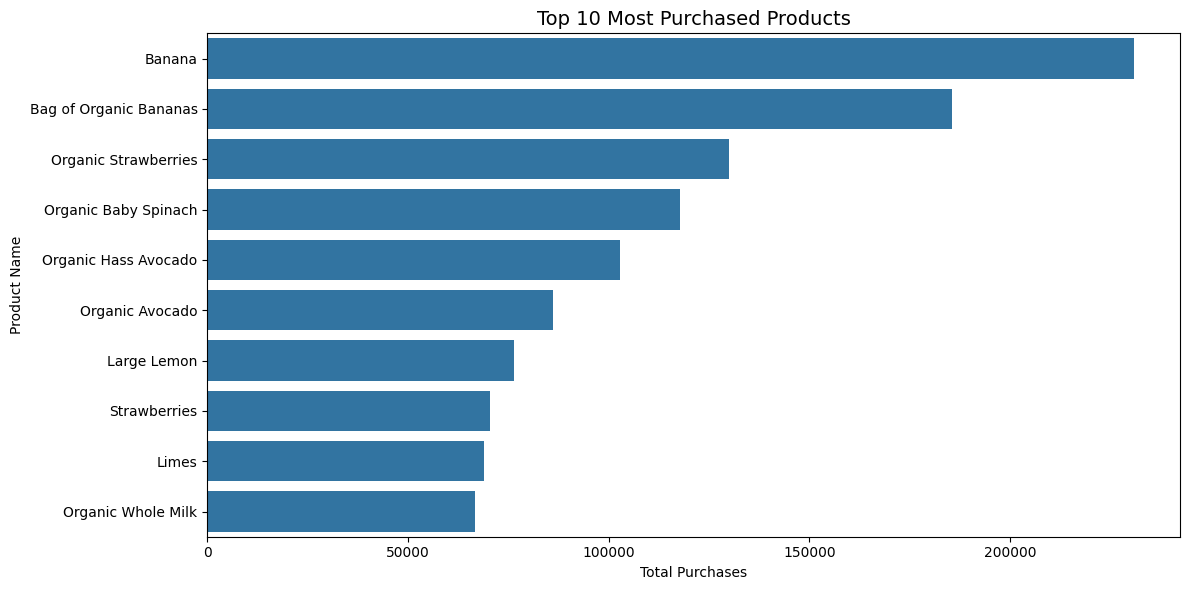

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

query = """
SELECT
    p.product_name,
    COUNT(*) AS total_purchases
FROM (
    SELECT product_id FROM order_products_prior
    UNION ALL
    SELECT product_id FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
GROUP BY p.product_id, p.product_name
ORDER BY total_purchases DESC
LIMIT 10;
"""

top_products = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_products,
    x='total_purchases',
    y='product_name'
)

plt.title('Top 10 Most Purchased Products', fontsize=14)
plt.xlabel('Total Purchases')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

**Top 10 Departments by Purchase Volume**

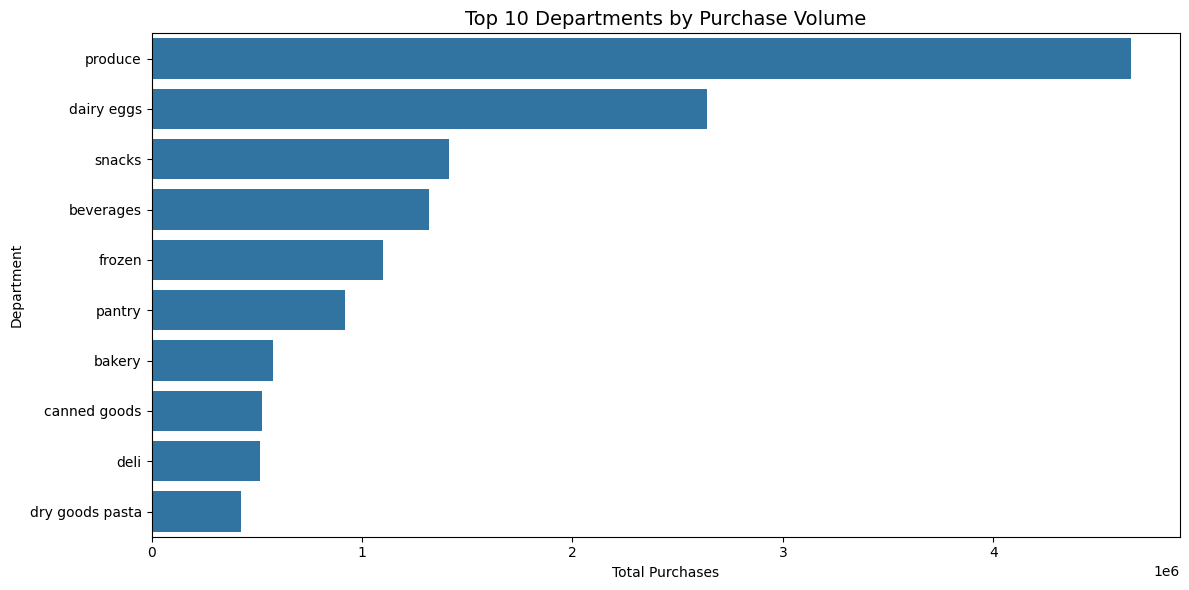

In [74]:
query = """
SELECT
    d.department,
    COUNT(*) AS total_purchases
FROM (
    SELECT product_id FROM order_products_prior
    UNION ALL
    SELECT product_id FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
JOIN departments d
    ON p.department_id = d.department_id
GROUP BY d.department
ORDER BY total_purchases DESC
LIMIT 10;
"""

top_departments = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_departments,
    x='total_purchases',
    y='department'
)

plt.title('Top 10 Departments by Purchase Volume', fontsize=14)
plt.xlabel('Total Purchases')
plt.ylabel('Department')
plt.tight_layout()
plt.show()

**Reorder Rate by Department**

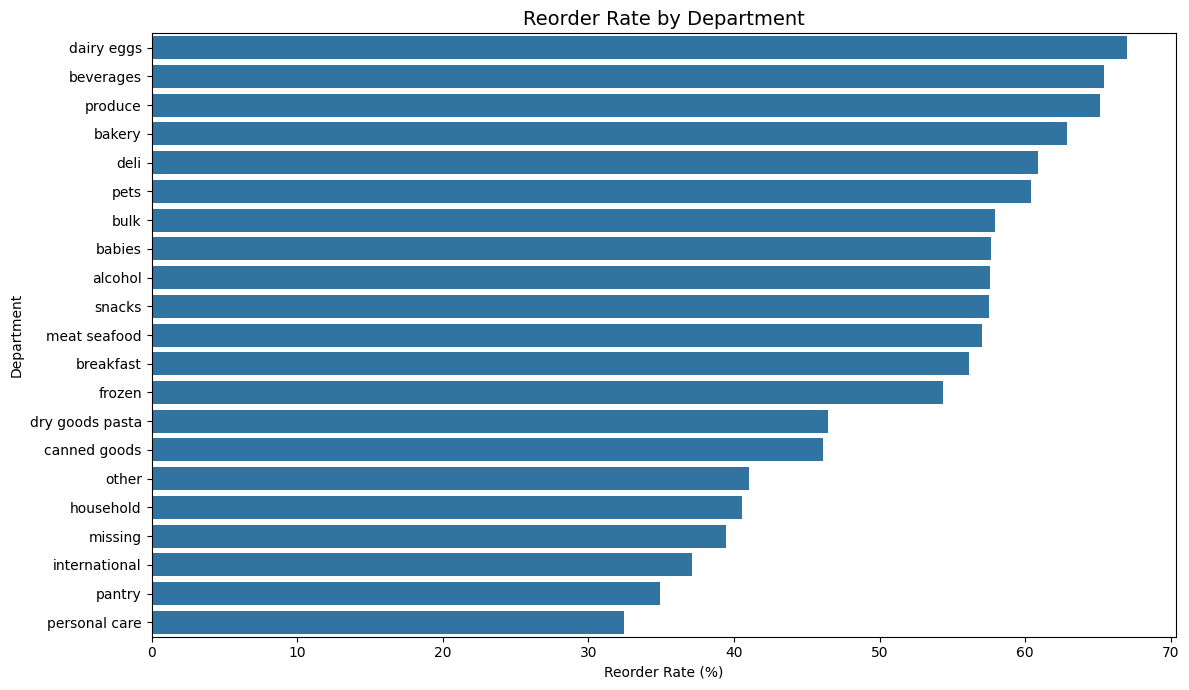

In [75]:
query = """
SELECT
    d.department,
    COUNT(*) AS total_products,
    SUM(op.reordered) AS total_reorders,
    ROUND(
        100.0 * SUM(op.reordered) / COUNT(*), 2
    ) AS reorder_rate
FROM (
    SELECT product_id, reordered FROM order_products_prior
    UNION ALL
    SELECT product_id, reordered FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
JOIN departments d
    ON p.department_id = d.department_id
GROUP BY d.department
ORDER BY reorder_rate DESC;
"""

reorder_departments = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=reorder_departments,
    x='reorder_rate',
    y='department'
)

plt.title('Reorder Rate by Department', fontsize=14)
plt.xlabel('Reorder Rate (%)')
plt.ylabel('Department')
plt.tight_layout()
plt.show()

**Top 10 Product Pairs Frequently Purchased Together**

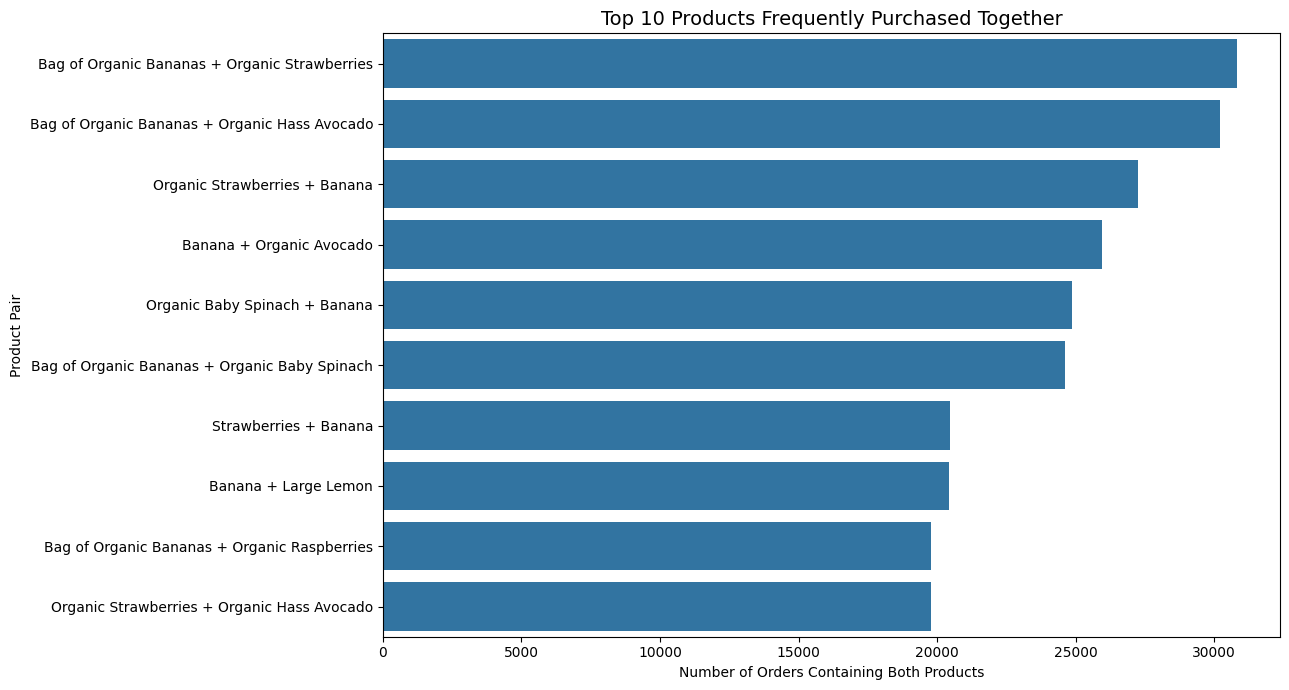

In [76]:
query = """
WITH combined AS (
    SELECT order_id, product_id FROM order_products_prior
    UNION ALL
    SELECT order_id, product_id FROM order_products_train
),
product_pairs AS (
    SELECT
        a.product_id AS product_1,
        b.product_id AS product_2,
        COUNT(*) AS pair_count
    FROM combined a
    JOIN combined b
        ON a.order_id = b.order_id
       AND a.product_id < b.product_id
    GROUP BY a.product_id, b.product_id
)
SELECT
    p1.product_name || ' + ' || p2.product_name AS product_pair,
    pp.pair_count
FROM product_pairs pp
JOIN products p1 ON pp.product_1 = p1.product_id
JOIN products p2 ON pp.product_2 = p2.product_id
ORDER BY pp.pair_count DESC
LIMIT 10;
"""

product_pairs = pd.read_sql_query(query, conn)

plt.figure(figsize=(13, 7))
sns.barplot(
    data=product_pairs,
    x='pair_count',
    y='product_pair'
)

plt.title('Top 10 Products Frequently Purchased Together', fontsize=14)
plt.xlabel('Number of Orders Containing Both Products')
plt.ylabel('Product Pair')
plt.tight_layout()
plt.show()

**Average Basket Size by Hour**

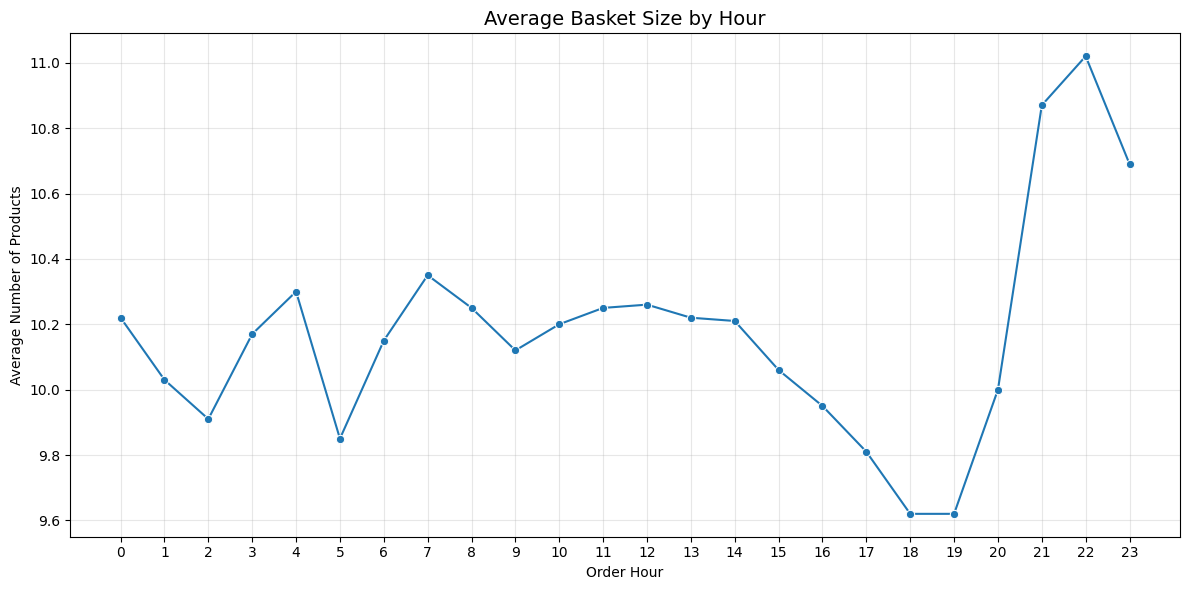

In [77]:
query = """
WITH combined AS (
    SELECT order_id FROM order_products_prior
    UNION ALL
    SELECT order_id FROM order_products_train
),
basket_size AS (
    SELECT
        order_id,
        COUNT(*) AS total_products
    FROM combined
    GROUP BY order_id
)
SELECT
    o.order_hour_of_day,
    ROUND(AVG(b.total_products), 2) AS avg_basket_size
FROM basket_size b
JOIN orders o
    ON b.order_id = o.order_id
GROUP BY o.order_hour_of_day
ORDER BY o.order_hour_of_day;
"""

basket_hour = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=basket_hour,
    x='order_hour_of_day',
    y='avg_basket_size',
    marker='o'
)

plt.title('Average Basket Size by Hour', fontsize=14)
plt.xlabel('Order Hour')
plt.ylabel('Average Number of Products')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Order Distribution by Hour**

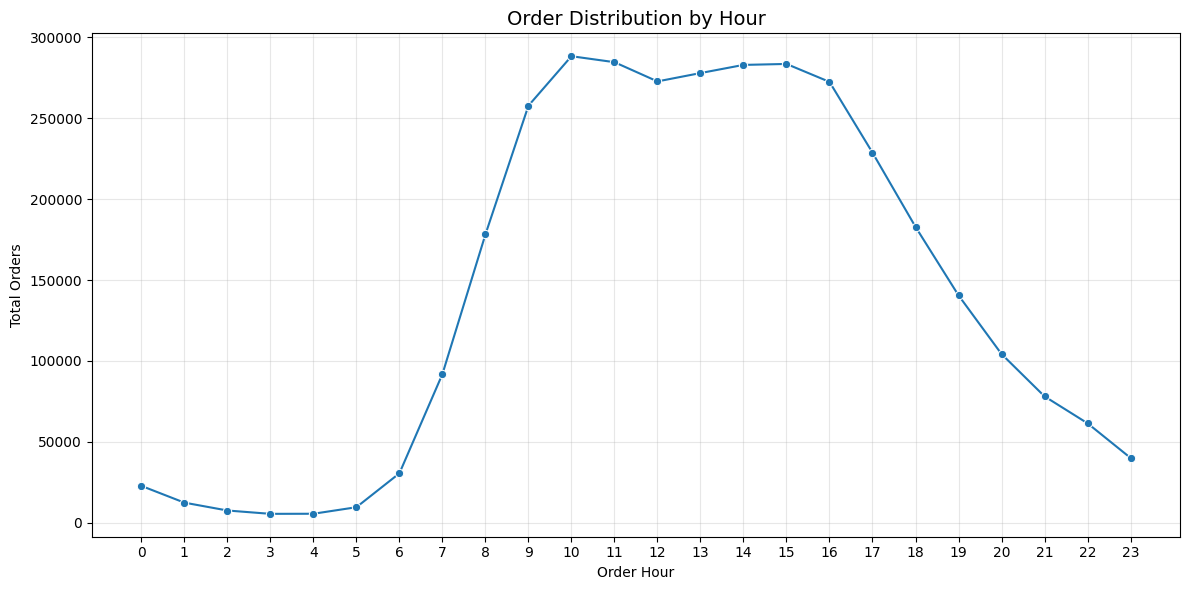

In [78]:
query = """
SELECT
    order_hour_of_day,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_hour_of_day
ORDER BY order_hour_of_day;
"""

orders_hour = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=orders_hour,
    x='order_hour_of_day',
    y='total_orders',
    marker='o'
)

plt.title('Order Distribution by Hour', fontsize=14)
plt.xlabel('Order Hour')
plt.ylabel('Total Orders')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Order Distribution by Day**

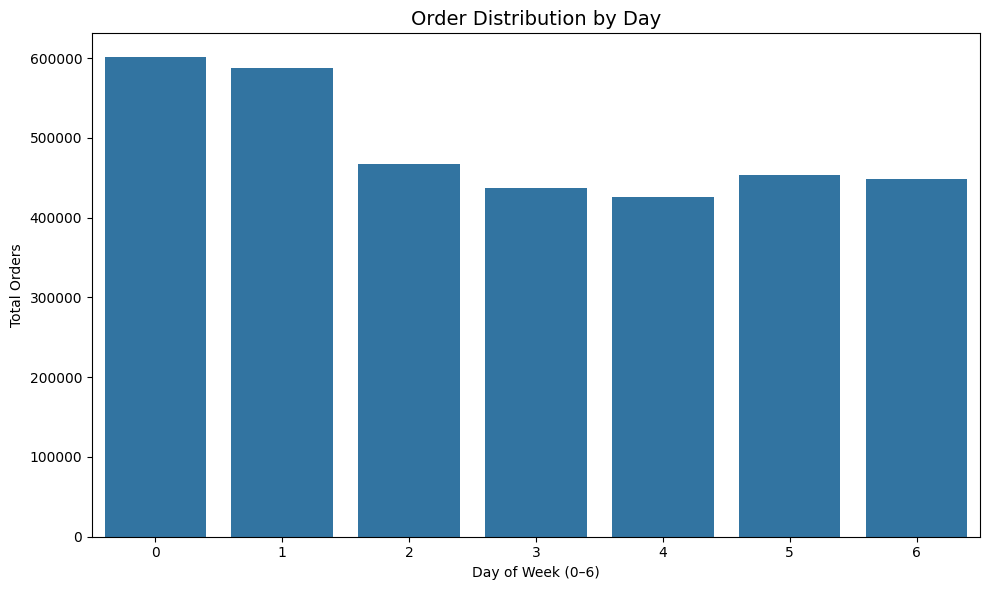

In [79]:
query = """
SELECT
    order_dow,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_dow
ORDER BY order_dow;
"""

orders_day = pd.read_sql_query(query, conn)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=orders_day,
    x='order_dow',
    y='total_orders'
)

plt.title('Order Distribution by Day', fontsize=14)
plt.xlabel('Day of Week (0–6)')
plt.ylabel('Total Orders')
plt.tight_layout()
plt.show()

**Customer Order Frequency Distribution**

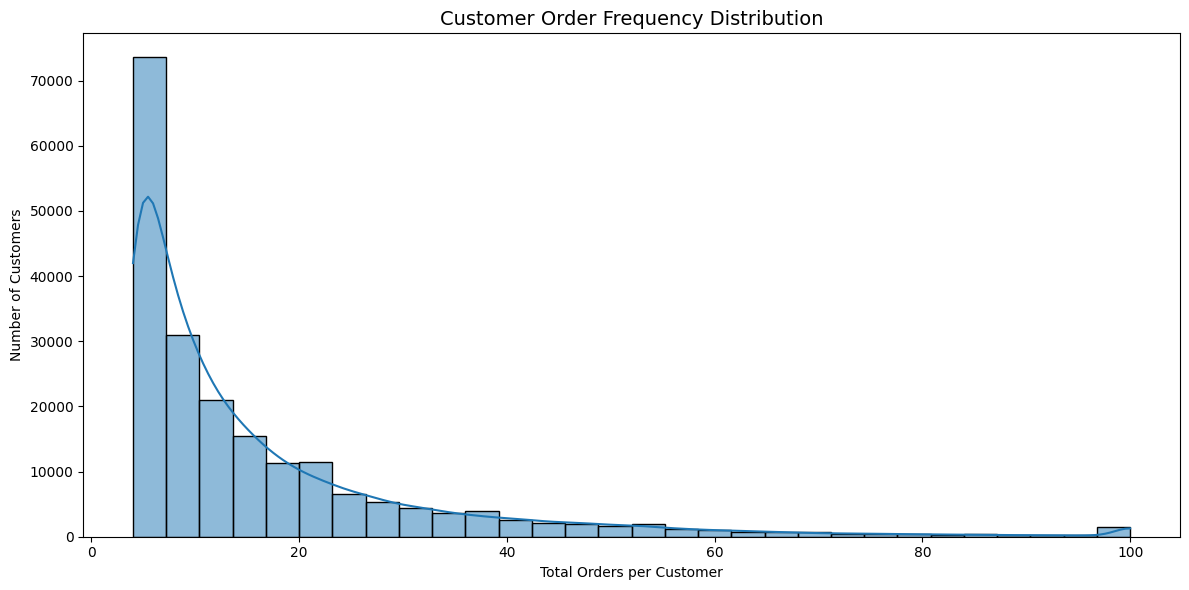

In [80]:
query = """
SELECT
    user_id,
    COUNT(order_id) AS total_orders
FROM orders
GROUP BY user_id;
"""

customer_frequency = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))
sns.histplot(
    data=customer_frequency,
    x='total_orders',
    bins=30,
    kde=True
)

plt.title('Customer Order Frequency Distribution', fontsize=14)
plt.xlabel('Total Orders per Customer')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

**Reorder Rate by Aisle**

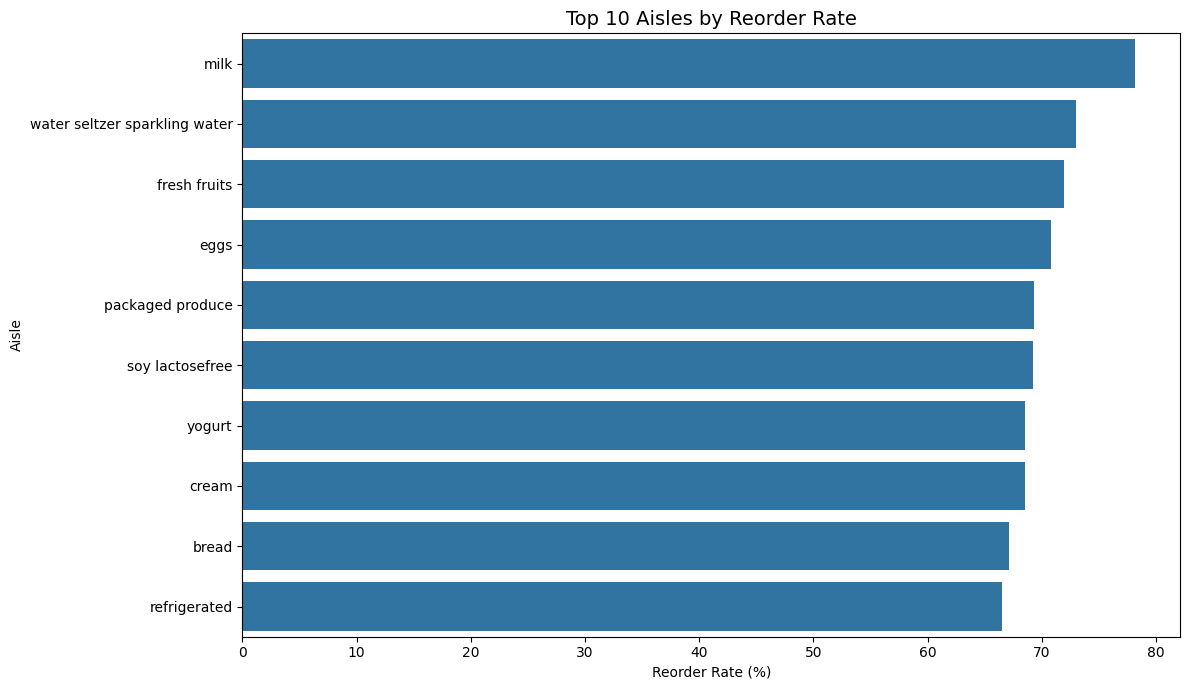

In [81]:
query = """
SELECT
    a.aisle,
    COUNT(*) AS total_products,
    SUM(op.reordered) AS total_reorders,
    ROUND(100.0 * SUM(op.reordered) / COUNT(*), 2) AS reorder_rate
FROM (
    SELECT product_id, reordered FROM order_products_prior
    UNION ALL
    SELECT product_id, reordered FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
JOIN aisles a
    ON p.aisle_id = a.aisle_id
GROUP BY a.aisle
HAVING COUNT(*) >= 1000
ORDER BY reorder_rate DESC
LIMIT 10;
"""

reorder_aisles = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=reorder_aisles,
    x='reorder_rate',
    y='aisle'
)

plt.title('Top 10 Aisles by Reorder Rate', fontsize=14)
plt.xlabel('Reorder Rate (%)')
plt.ylabel('Aisle')
plt.tight_layout()
plt.show()

**Average Days Between Orders**

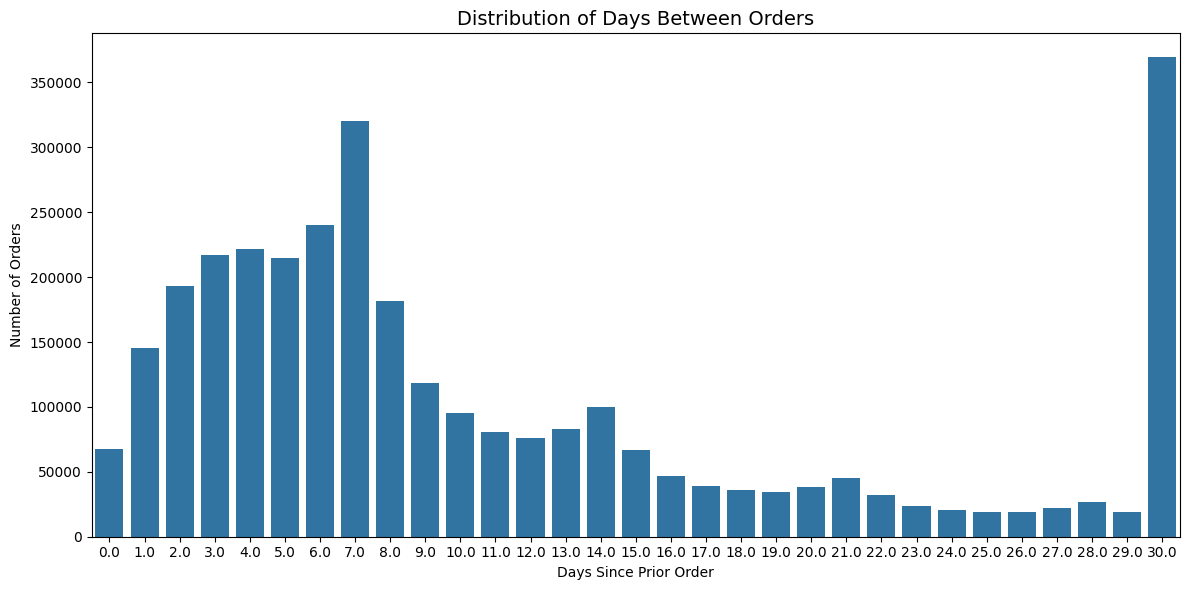

In [82]:
query = """
SELECT
    days_since_prior_order,
    COUNT(*) AS total_orders
FROM orders
WHERE days_since_prior_order IS NOT NULL
GROUP BY days_since_prior_order
ORDER BY days_since_prior_order;
"""

order_intervals = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=order_intervals,
    x='days_since_prior_order',
    y='total_orders'
)

plt.title('Distribution of Days Between Orders', fontsize=14)
plt.xlabel('Days Since Prior Order')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()

**Top 10 Products by Reorder Count**

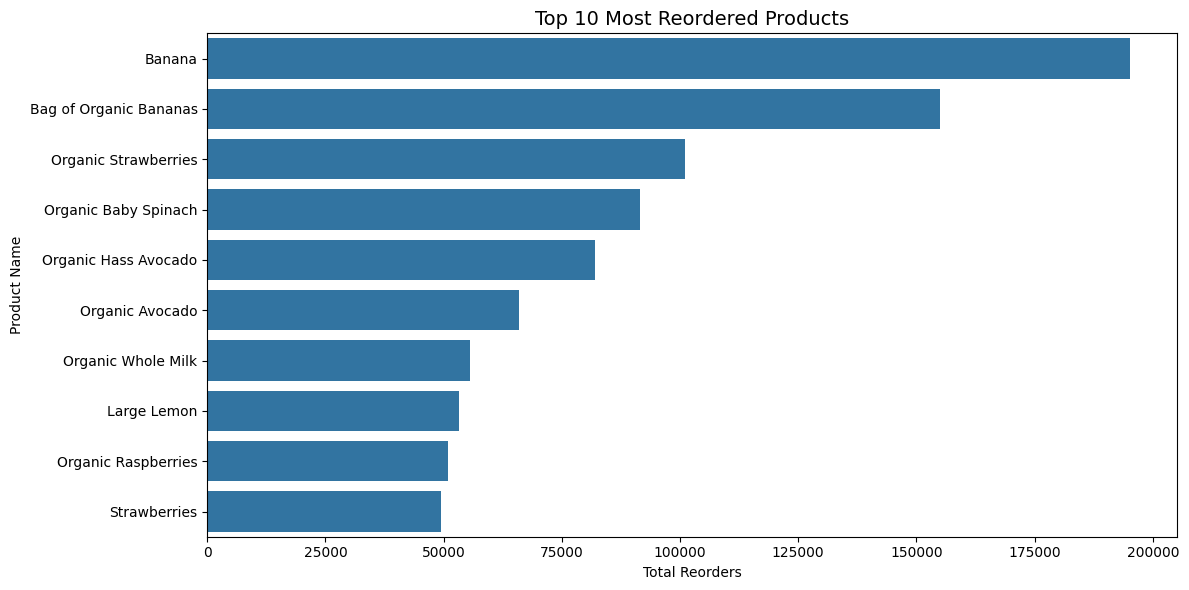

In [83]:
query = """
SELECT
    p.product_name,
    SUM(op.reordered) AS total_reorders
FROM (
    SELECT product_id, reordered FROM order_products_prior
    UNION ALL
    SELECT product_id, reordered FROM order_products_train
) op
JOIN products p
    ON op.product_id = p.product_id
GROUP BY p.product_id, p.product_name
ORDER BY total_reorders DESC
LIMIT 10;
"""

top_reorders = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_reorders,
    x='total_reorders',
    y='product_name'
)

plt.title('Top 10 Most Reordered Products', fontsize=14)
plt.xlabel('Total Reorders')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()